# 01 · Exploratory Data Analysis : 
**Goal of this notebook:** answer the questions that decide our whole strategy *before* we model anything.
1. How is `validation.csv` related to `train_test.csv` in time? From here we will decided either the split will be random or time-based
2. What data-quality problems exist? (decides the cleaning)
3. Which features are trustworthy, and which are traps? decides whicg features are important
4. What will the December chart need? (decides the inference design)

In [13]:
import os, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path(os.environ.get("DATA_DIR", Path.home() / "Downloads"))

def find(stem):
    names = [stem, stem.replace("_", "-")]
    for n in names:                                  
        if (DATA_DIR / f"{n}.csv").is_file():
            return str(DATA_DIR / f"{n}.csv")
    for n in names:                                  
        hits = sorted(glob.glob(str(DATA_DIR / f"{n} (*).csv")))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Could not find {stem}.csv in {DATA_DIR}. Edit DATA_DIR above.")

tr  = pd.read_csv(find("train_test"), parse_dates=["date"])
va  = pd.read_csv(find("validation"), parse_dates=["date"])
dec = pd.read_csv(find("december_chart_inputs"), parse_dates=["date"])
print("train_test:", tr.shape, "| validation:", va.shape, "| december:", dec.shape)
tr.head()

train_test: (48000, 14) | validation: (12000, 13) | december: (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 1 · Check Dates
If validation is *after* training, a random split would bad choice for us. We must validate on the future.

In [12]:
print("train      :", tr.date.min().date(), "→", tr.date.max().date())
print("validation :", va.date.min().date(), "→", va.date.max().date())
print("december   :", dec.date.min().date(), "→", dec.date.max().date())

train      : 2025-01-01 → 2025-10-31
validation : 2025-11-01 → 2025-12-31
december   : 2025-12-01 → 2025-12-31


**Finding:** train = Jan–Oct 2025, validation = Nov–Dec 2025 → the hidden set is the **future**. We will use a **forward-chaining (time-based) split**, never a random one.

## 2 · Data Analysis :
Missing values, duplicates, impossible values

In [14]:
print("Missing (train):\n", tr.isna().sum()[lambda s: s > 0], "\n")
print("Missing (val):\n",   va.isna().sum()[lambda s: s > 0], "\n")
print("Duplicate load_id:", tr.load_id.duplicated().sum(), va.load_id.duplicated().sum())
print("Negative weights  : train", (tr.weight < 0).sum(), "| val", (va.weight < 0).sum())
print("Weight == ±47,500 : train", (tr.weight.abs() == 47500).sum(), "(upper clip)")
print("Distance == 70 (floor):", (tr.distance == 70).sum())

Missing (train):
 weight          300
market_index    374
dtype: int64 

Missing (val):
 weight          165
market_index    249
dtype: int64 

Duplicate load_id: 0 0
Negative weights  : train 292 | val 145
Weight == ±47,500 : train 1204 (upper clip)
Distance == 70 (floor): 48


**Findings**
- `weight` is missing in ~0.6% of rows **and has negative values** (sign errors → use `abs()`); capped at 47,500.
- `market_index` is missing in ~0.8% of rows (we will see below that it can be recovered from other loads on the same day).
- `distance` has a floor of 70 miles (minimum-distance rule, not an error).
- No duplicate IDs.

## 3 · The target: `posted_rate` and rate-per-mile

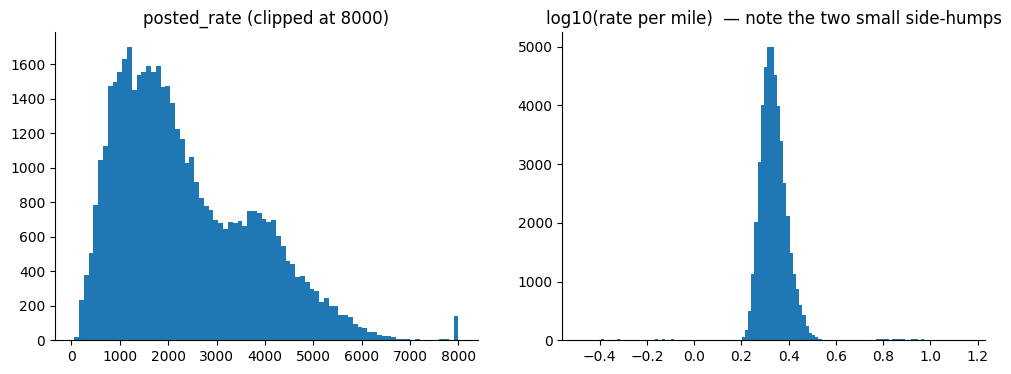

0.000     0.33
0.005     0.75
0.010     1.67
0.500     2.15
0.990     3.18
0.995     6.31
1.000    14.13
Name: rpm, dtype: float64


In [15]:
tr["rpm"] = tr.posted_rate / tr.distance
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(tr.posted_rate.clip(upper=8000), bins=80); ax[0].set_title("posted_rate (clipped at 8000)")
ax[1].hist(np.log10(tr.rpm), bins=120); ax[1].set_title("log10(rate per mile)  — note the two small side-humps")
plt.show()
print(tr.rpm.quantile([0, .005, .01, .5, .99, .995, 1]).round(2))

In [16]:
print(np.histogram(tr.rpm, bins=[0, .5, 1, 1.5, 2, 3, 4, 5, 7, 10, 15])[0])
bad_hi, bad_lo = (tr.rpm > 5).sum(), (tr.rpm < 1.2).sum()
print(f"rpm > 5 : {bad_hi}   rpm < 1.2 : {bad_lo}   → {(bad_hi+bad_lo)/len(tr):.2%} of rows")

[  103   226     8 12604 34287   432    23   110   158    49]
rpm > 5 : 317   rpm < 1.2 : 335   → 1.36% of rows


**Finding — corrupted labels.** ~1.4% of rates are 3–5× too high or ~0.28× too low. They are spread evenly over equipment, month and distance (checked), so they are **random label noise**, not a pattern a model can learn. We will:
- train with outliers removed / a robust loss,
- evaluate on **both** all rows and clean rows (the hidden metric probably includes some noise).

## 4 · Rate structure: distance, equipment, weight

equipment
Dry Van    2.046
Flatbed    2.220
Reefer     2.312
Name: rpm, dtype: float64 

distance
(0, 150]        2.873
(150, 300]      2.630
(300, 500]      2.400
(500, 800]      2.228
(800, 1200]     2.122
(1200, 2000]    2.025
(2000, 4000]    1.912
Name: rpm, dtype: float64 

weight
(0, 15000]        2.057
(15000, 25000]    2.073
(25000, 35000]    2.137
(35000, 44000]    2.203
(44000, 47500]    2.212
Name: rpm, dtype: float64


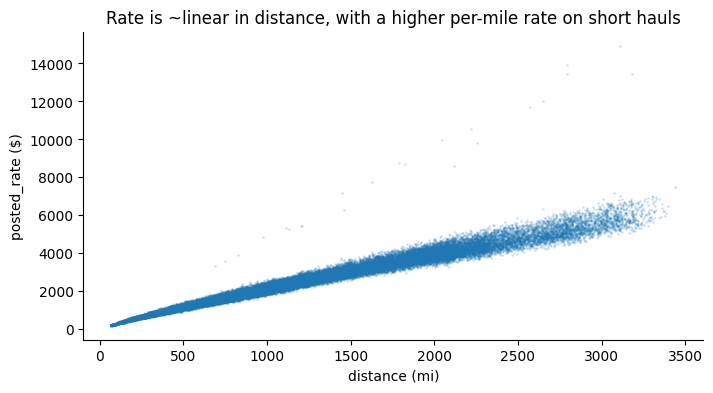

In [17]:
clean = tr[(tr.rpm > 1.4) & (tr.rpm < 5)]
print(clean.groupby("equipment").rpm.median().round(3), "\n")
print(clean.groupby(pd.cut(clean.distance, [0,150,300,500,800,1200,2000,4000]), observed=True).rpm.median().round(3), "\n")
print(clean.groupby(pd.cut(clean.weight.abs(), [0,15000,25000,35000,44000,47500]), observed=True).rpm.median().round(3))
fig, ax = plt.subplots(figsize=(8,4)); ax.scatter(clean.distance, clean.posted_rate, s=1, alpha=.15)
ax.set_xlabel("distance (mi)"); ax.set_ylabel("posted_rate ($)"); ax.set_title("Rate is ~linear in distance, with a higher per-mile rate on short hauls"); plt.show()

**Finding:** rate is almost linear in distance, but **rate/mile falls with distance** (short hauls cost more per mile) and Reefer > Flatbed > Dry Van. This tells us to model **rate-per-mile (or log-rate)** and give the model `log(distance)`.

## 5 · Geography: coordinates, route, unseen cities

In [18]:
def hav(a,b,c,d):
    a,b,c,d = map(np.radians,[a,b,c,d]); x = np.sin((c-a)/2)**2 + np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2
    return 3958.8*2*np.arcsin(np.sqrt(x))
for d in (tr, va):
    d["hav"] = hav(d.pickup_lat, d.pickup_lon, d.delivery_lat, d.delivery_lon)
print("distance / haversine:"); print((tr.distance/tr.hav).describe().round(3))
tr_cities = set(tr.pickup) | set(tr.delivery)
unseen = (set(va.pickup) | set(va.delivery)) - tr_cities
mask = va.pickup.isin(unseen) | va.delivery.isin(unseen)
print("\nCities in validation but NEVER in train:", sorted(unseen))
print(f"Validation rows touching an unseen city: {mask.sum()} ({mask.mean():.1%})")
lex = tr[(tr.pickup=="Lexington") & (tr.delivery=="Fort Wayne")]
print("\nLexington→Fort Wayne in train:", len(lex), "loads; distance varies", lex.distance.min(), "-", lex.distance.max())

distance / haversine:
count    48000.000
mean         1.195
std          0.144
min          1.058
25%          1.165
50%          1.182
75%          1.205
max          9.635
dtype: float64

Cities in validation but NEVER in train: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation rows touching an unseen city: 1447 (12.1%)

Lexington→Fort Wayne in train: 32 loads; distance varies 346.3 - 384.5


**Findings**
- The coordinates are *approximate/synthetic* (e.g. Baltimore at lon −72.7) — they are consistent per city but not real GPS. `distance` is the trustworthy route measure (and is slightly noisy per load).
- **8 cities appear only in validation** (12.1% of rows). A model that memorises city names / route IDs will fail there. **Design rule: build features that generalise from geography and distance, and test our validation with held-out cities.**
- Laredo's latitude (25.5) is outside the training range → trees can't extrapolate; another reason to rely on distance.

## 6 · `market_index`: looks weak at row level — but it isn't

row-level corr(market_index, rpm): 0.173
avg std WITHIN a day : 0.0249
std of daily means   : 0.1665
daily autocorr lag-1 : 0.927
corr(daily market_index, daily rate residual): 0.695


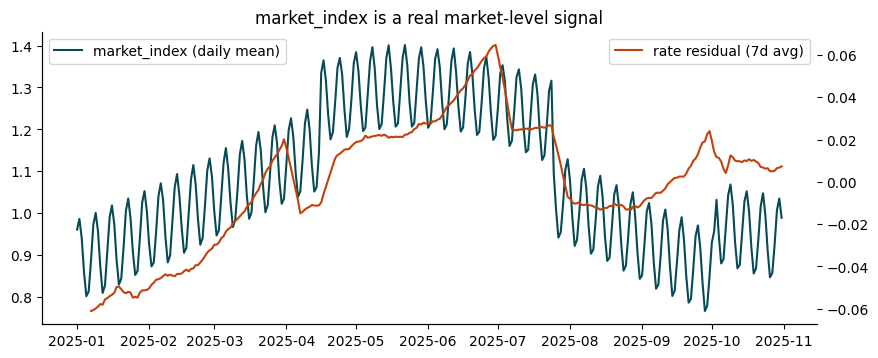

In [19]:
# Row-level correlation looks tiny...
print("row-level corr(market_index, rpm):", round(clean.market_index.corr(clean.rpm), 3))
# ...but market_index is really a smooth DAILY series with tiny within-day noise:
print("avg std WITHIN a day :", round(tr.groupby("date").market_index.std().mean(), 4))
print("std of daily means   :", round(tr.groupby("date").market_index.mean().std(), 4))
print("daily autocorr lag-1 :", round(tr.groupby("date").market_index.mean().autocorr(1), 3))

# remove the distance/equipment effect, then compare DAILY averages
c = clean.copy(); c["lr"] = np.log(c.rpm)
c["res"] = c.lr - c.groupby(["equipment", pd.cut(c.distance,[0,150,300,500,800,1200,2000,4000])], observed=True).lr.transform("mean")
daily = pd.concat([c.groupby("date").market_index.mean(), c.groupby("date").res.mean()], axis=1)
print("corr(daily market_index, daily rate residual):", round(daily.corr().iloc[0,1], 3))
fig, ax = plt.subplots(figsize=(10,3.8)); ax2 = ax.twinx()
ax.plot(daily.index, daily.market_index, color="#064A56", label="market_index (daily mean)")
ax2.plot(daily.index, daily.res.rolling(7).mean(), color="#C2410C", label="rate residual (7d avg)")
ax.set_title("market_index is a real market-level signal"); ax.legend(loc="upper left"); ax2.legend(loc="upper right"); plt.show()

**Finding:** `market_index` is one clean number per day (plus tiny noise) and its daily level correlates ~0.70 with the daily rate level. It's a **legitimate, strong feature**. Two consequences:
- Missing values can be filled with that day's median across other loads.
- `december_chart_inputs.csv` has no `market_index`, **but `validation.csv` contains it for every December day** → we can look up December's daily index from `validation.csv` (features only, no labels, so no leakage).

## 7 · `quote_signal`: the trap

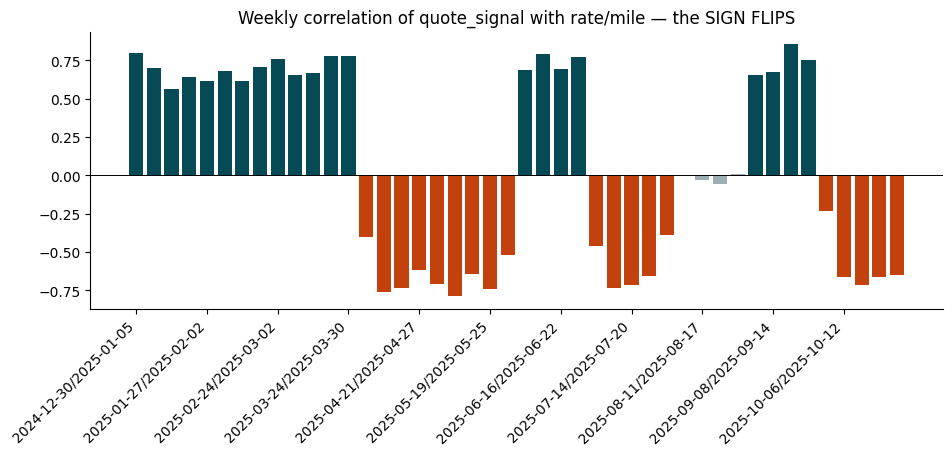

overall corr: 0.074
validation quote_signal: mean 2.051 std 0.22


In [20]:
tr["wk"] = tr.date.dt.to_period("W")
w = tr.groupby("wk").apply(lambda x: x.quote_signal.corr(x.rpm.clip(upper=5)), include_groups=False)
fig, ax = plt.subplots(figsize=(11,3.6)); ax.bar(w.index.astype(str), w.values, color=np.where(w.values>0.1,"#064A56",np.where(w.values<-0.1,"#C2410C","#9DAFB3")))
ax.set_xticks(range(0,len(w),4)); ax.set_xticklabels(w.index.astype(str)[::4], rotation=45, ha="right")
ax.axhline(0, color="k", lw=.7); ax.set_title("Weekly correlation of quote_signal with rate/mile — the SIGN FLIPS"); plt.show()
print("overall corr:", round(tr.quote_signal.corr(tr.rpm.clip(upper=5)), 3))
print("validation quote_signal: mean", round(va.quote_signal.mean(),3), "std", round(va.quote_signal.std(),3))

**Finding — a regime-dependent trap.** Within a regime `quote_signal` is strongly related to rate (|r| ≈ 0.45), but the relationship is **positive in Jan–Mar, Jun, Sep, negative in Apr–May, Jul, Oct, and ≈ 0 in Aug**. The overall correlation (~0.05) hides this. A random split would let a model memorise the regime and score brilliantly; on the *future* it can be badly wrong, because we cannot know which regime Nov/Dec is in.

**Decision (to be proven in the modelling step with a backtest):** exclude `quote_signal` from the production model, and show the evidence in the report.

## 8 · Calendar effects

In [21]:
print("Rate residual by month:\n", c.groupby(c.date.dt.month).res.mean().round(3).to_dict())
print("By weekday (0=Mon):", c.groupby(c.date.dt.dayofweek).res.mean().round(3).to_dict())
print("Loads/day  train:", round(tr.groupby("date").size().mean()), "| val:", round(va.groupby("date").size().mean()))

Rate residual by month:
 {1: -0.054, 2: -0.04, 3: -0.004, 4: 0.001, 5: 0.024, 6: 0.048, 7: 0.019, 8: -0.012, 9: 0.006, 10: 0.008}
By weekday (0=Mon): {0: -0.008, 1: -0.001, 2: 0.008, 3: 0.01, 4: 0.006, 5: -0.004, 6: -0.011}
Loads/day  train: 158 | val: 197


**Finding:** there's a slow upward drift Jan→Jun then a fall, mostly explained by `market_index`; weekday effects are tiny (~±1%); no obvious holiday spikes. We only have **10 months** of history, so we cannot learn a December seasonal pattern from dates alone — December must be driven by `market_index` (known from `validation.csv`). That is exactly why the December chart is a good test of whether the model is sensible.

## Summary of decisions carried into the next steps
| # | Finding | Decision |
|---|---|---|
| 1 | Validation is Nov–Dec (future) | Time-based / forward-chaining validation |
| 2 | 1.4% corrupted labels | Remove for training; report metrics on all + clean |
| 3 | Negative / missing weight | `abs()` + impute with median by equipment |
| 4 | Missing `market_index` | Fill with same-day median |
| 5 | 8 unseen cities (12% of val) | Geography/distance features; city-holdout check |
| 6 | `market_index` = daily market level | Keep; use val's daily value for December |
| 7 | `quote_signal` flips sign | Exclude (prove with backtest) |
| 8 | Rate/mile falls with distance | Predict log-rate / rate-per-mile |